# 06 – Baseline (BRFSS 2015)


**Mục đích:** tạo **mốc so sánh**. Mô hình chính ở notebook 07 chỉ có giá trị nếu vượt được các mốc này.

**Thực hiện**
1. `DummyClassifier` (`most_frequent` và `stratified`).
2. Logistic Regression tham số mặc định, **không** xử lý mất cân bằng, dùng pipeline của notebook 05 (imputer, winsorize BMI, đặc trưng mới, scaler).

Đánh giá bằng **Stratified 5-fold CV trên tập train**; tập test không được dùng. Kết quả ghi vào `logs/experiment_log.csv`, bảng số liệu lưu `logs/results_06_baseline.csv`, hình lưu `DATA/figures/`.


## 0. Cấu hình, nạp dữ liệu và hàm dùng chung
Phần này giống hệt giữa notebook 06 và 07, để hai notebook dùng **cùng một cách chia dữ liệu, cùng pipeline và cùng bộ CV**.

In [1]:
from pathlib import Path
import csv, os, time, warnings
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support,
                             roc_auc_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# ---------------- CẤU HÌNH (sửa ở đây) ----------------
RUNNER       = "Quang Khu"          # ghi vào Experiment Log
TARGET       = "Diabetes_binary"    # đổi thành "Diabetes_012" nếu nhóm quyết định dùng nhãn 3 lớp
RAW_FILE     = "diabetes.csv"       # file trong DATA/raw/ (nếu dùng 3 lớp, đổi tên file tương ứng)
DEDUP        = False                # False = giữ dòng trùng (giống notebook 05); True = xóa trùng trước khi chia (giống notebook 03)
RANDOM_STATE = 42                   # dùng chung cả nhóm
TEST_SIZE    = 0.20
QUICK        = False                # True = chạy thử nhanh trên mẫu nhỏ để kiểm tra code
QUICK_N      = 20000

CLASS_NAMES_BY_TARGET = {
    "Diabetes_binary": ["Không tiểu đường", "Tiểu đường/tiền TĐ"],
    "Diabetes_012":    ["Không bệnh", "Tiền tiểu đường", "Tiểu đường"],
}

In [2]:
def find_project_root():
    """Giống notebook 04/05: đi ngược lên đến thư mục có DATA/ hoặc sources/."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "DATA").is_dir() or (base / "sources").is_dir():
            return base
    raise FileNotFoundError("Không tìm thấy thư mục DATA/ hoặc sources/. Hãy mở notebook trong thư mục dự án.")

ROOT = find_project_root()
RAW_PATH = next((p for p in [ROOT / "DATA" / "raw" / RAW_FILE, ROOT / "sources" / RAW_FILE] if p.is_file()), None)
if RAW_PATH is None:
    raise FileNotFoundError(f"Không tìm thấy {RAW_FILE} trong DATA/raw/ hoặc sources/.")

FIG_DIR = ROOT / "DATA" / "figures"      # cùng chỗ với hình của notebook 02
LOG_DIR = ROOT / "logs"                  # Experiment Log dùng chung cả nhóm
FIG_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH = LOG_DIR / "experiment_log.csv"
print("Project:", ROOT)
print("Dữ liệu:", RAW_PATH.relative_to(ROOT))

Project: d:\May Hoc\CK_ML\MAY_HOC_NHOM\Do_An_Cuoi_Ky
Dữ liệu: DATA\raw\diabetes.csv


In [3]:
df = pd.read_csv(RAW_PATH)
if TARGET not in df.columns:
    raise ValueError(f"Không có cột {TARGET}. Các cột hiện có: {list(df.columns)}")
n_raw = len(df)
if DEDUP:
    df = df.drop_duplicates(keep="first").reset_index(drop=True)
    print(f"Xóa trùng: {n_raw:,} -> {len(df):,} dòng")
else:
    print(f"Giữ dòng trùng: {n_raw:,} dòng (trong đó {df.duplicated().sum():,} dòng trùng)")

X = df.drop(columns=TARGET).copy()
y = df[TARGET].astype(int).copy()

# Chia y hệt notebook 05: 80/20, phân tầng, seed 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
del X_test, y_test        # KHÔNG dùng tập test ở giữa kỳ; chỉ dùng một lần ở cuối

if QUICK:
    X_train, _, y_train, _ = train_test_split(
        X_train, y_train, train_size=QUICK_N, stratify=y_train, random_state=RANDOM_STATE)

X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
yv = y_train.values

CLASSES = sorted(y_train.unique().tolist())
CLASS_NAMES = CLASS_NAMES_BY_TARGET.get(TARGET, [str(c) for c in CLASSES])
counts = y_train.value_counts().sort_index()
FOCUS_IDX = int(np.argmin(counts.values))      # lớp hiếm nhất = lớp cần chú ý
FOCUS_NAME = CLASS_NAMES[FOCUS_IDX]
DATA_TAG = f"{TARGET}|{'dedup' if DEDUP else 'giữ trùng'}|{'QUICK' if QUICK else 'đầy đủ'}"

print("X_train:", X_train.shape, "| Số lớp:", len(CLASSES), "| Lớp cần chú ý:", FOCUS_NAME)
print(pd.DataFrame({"số mẫu": counts.values, "tỷ lệ": (counts / counts.sum()).round(4).values},
                   index=CLASS_NAMES))

Giữ dòng trùng: 253,680 dòng (trong đó 24,206 dòng trùng)
X_train: (202944, 21) | Số lớp: 2 | Lớp cần chú ý: Tiểu đường/tiền TĐ
                    số mẫu   tỷ lệ
Không tiểu đường    174667  0.8607
Tiểu đường/tiền TĐ   28277  0.1393


In [4]:
# ----- Sao chép từ notebook 05 (nên chuyển vào src/ để cả nhóm import chung, tránh lệch phiên bản) -----
ORDINAL = ["Age", "Education", "Income", "GenHlth"]

class Winsorizer(BaseEstimator, TransformerMixin):
    """Cắt BMI về các phân vị lower/upper đã ước lượng trong fit."""
    def __init__(self, columns=("BMI",), lower=0.01, upper=0.99):
        self.columns = columns
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.bounds_ = {col: (X[col].quantile(self.lower), X[col].quantile(self.upper))
                        for col in self.columns}
        return self

    def transform(self, X):
        out = X.copy()
        for col, (low, high) in self.bounds_.items():
            out[col] = out[col].clip(low, high)
        return out

class HealthFeatureEngineer(BaseEstimator, TransformerMixin):
    """Tạo các đặc trưng bổ sung, giữ các cột gốc."""
    def __init__(self, interaction=True):
        self.interaction = interaction

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        out = X.copy()
        out["BMI_WHO_Group"] = pd.cut(out["BMI"], [-np.inf, 18.5, 25, 30, np.inf],
                                      labels=False, right=False).astype(float)
        out["Comorbidity_Count"] = out[["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"]].sum(axis=1)
        out["Healthy_Lifestyle_Score"] = out[["PhysActivity", "Fruits", "Veggies"]].sum(axis=1)
        if self.interaction:
            out["Age_x_HighBP"] = out["Age"] * out["HighBP"]
        return out

    def get_feature_names_out(self, input_features=None):
        names = list(self.feature_names_in_) + ["BMI_WHO_Group", "Comorbidity_Count", "Healthy_Lifestyle_Score"]
        if self.interaction:
            names.append("Age_x_HighBP")
        return np.asarray(names, dtype=object)

def build_preprocessor(onehot_ordinal=False, add_engineered=True):
    steps = [("imputer", SimpleImputer(strategy="median").set_output(transform="pandas")),
             ("winsor", Winsorizer(columns=("BMI",)))]
    steps.append(("features", HealthFeatureEngineer() if add_engineered else "passthrough"))
    if onehot_ordinal:
        encoder = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
        columns = ColumnTransformer([("ordinal", encoder, ORDINAL)], remainder="passthrough",
                                    verbose_feature_names_out=False).set_output(transform="pandas")
        steps.append(("onehot", columns))
    steps.append(("scaler", StandardScaler()))
    return Pipeline(steps)

def make_pipe(model, fe=True, onehot=False):
    """Pipeline đầy đủ: tiền xử lý (notebook 05) + mô hình. Mỗi fold CV tự fit lại toàn bộ."""
    return Pipeline([("preprocessing", build_preprocessor(onehot_ordinal=onehot, add_engineered=fe)),
                     ("model", model)])

In [5]:
# Bộ CV dùng chung cho MỌI mô hình (cả 06 và 07)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

LOG_COLS = ["ngày", "người chạy", "mô hình", "tham số", "cách chia dữ liệu", "metric", "nhận xét"]
results, oof_pred = [], {}

def log_experiment(model_name, params, metric, note=""):
    """Ghi một dòng vào Experiment Log (mở được bằng Excel)."""
    new = not LOG_PATH.exists()
    split_desc = (f"{'xóa trùng' if DEDUP else 'giữ dòng trùng'}; 80/20 phân tầng rs={RANDOM_STATE}; "
                  f"Stratified 5-fold CV; target={TARGET}" + (" (QUICK)" if QUICK else ""))
    with open(LOG_PATH, "a", newline="", encoding="utf-8-sig" if new else "utf-8") as f:
        w = csv.writer(f)
        if new:
            w.writerow(LOG_COLS)
        w.writerow([date.today().isoformat(), RUNNER, model_name, params, split_desc, metric, note])

def evaluate_model(name, model, params="", note=""):
    """Stratified 5-fold CV trên tập train: tính metric, ghi log, lưu kết quả."""
    t0 = time.time()
    oof = np.zeros((len(yv), len(CLASSES)))
    fold_f1 = []
    for tr, va in cv.split(X_train, yv):
        m = clone(model).fit(X_train.iloc[tr], yv[tr])
        p = m.predict_proba(X_train.iloc[va])
        oof[va] = p
        fold_f1.append(f1_score(yv[va], np.array(CLASSES)[p.argmax(1)], average="macro"))
    pred = np.array(CLASSES)[oof.argmax(1)]

    prec, rec, f1, _ = precision_recall_fscore_support(yv, pred, labels=CLASSES, zero_division=0)
    if len(CLASSES) == 2:
        auc = roc_auc_score(yv, oof[:, 1])
        ap = average_precision_score(yv, oof[:, 1])
    else:
        auc = roc_auc_score(yv, oof, multi_class="ovr", average="macro")
        ap = np.nan
    row = {"Mô hình": name, "Dữ liệu": DATA_TAG,
           "Accuracy": accuracy_score(yv, pred),
           "Macro F1": f1_score(yv, pred, average="macro"),
           "Macro F1 (độ lệch)": float(np.std(fold_f1)),
           "ROC-AUC": auc, "PR-AUC": ap}
    for i, c in enumerate(CLASS_NAMES):
        row[f"Precision {c}"], row[f"Recall {c}"], row[f"F1 {c}"] = prec[i], rec[i], f1[i]
    row["Thời gian (s)"] = round(time.time() - t0, 1)
    results.append(row)
    oof_pred[name] = pred

    per_class = "; ".join(f"{c}: P={prec[i]:.3f} R={rec[i]:.3f}" for i, c in enumerate(CLASS_NAMES))
    metric = (f"Acc={row['Accuracy']:.4f}; MacroF1={row['Macro F1']:.4f}±{row['Macro F1 (độ lệch)']:.4f}; "
              f"ROC-AUC={auc:.4f}; PR-AUC={ap:.4f}; {per_class}")
    log_experiment(name, params, metric, note)
    print(f"[{name}] Acc={row['Accuracy']:.4f} | MacroF1={row['Macro F1']:.4f} | ROC-AUC={auc:.4f} | "
          f"Recall {FOCUS_NAME}={rec[FOCUS_IDX]:.3f} | {row['Thời gian (s)']:.0f}s")
    return row

def to_table(res):
    cols = ["Mô hình", "Accuracy", "Macro F1", "Macro F1 (độ lệch)", "ROC-AUC", "PR-AUC"]
    for c in CLASS_NAMES:
        cols += [f"Precision {c}", f"Recall {c}", f"F1 {c}"]
    return res[cols].round(4)

def plot_confusion(names, filename):
    """Hàng trên: số mẫu. Hàng dưới: chuẩn hóa theo hàng (chính là Recall từng lớp)."""
    fig, axes = plt.subplots(2, len(names), figsize=(5.2 * len(names), 9), squeeze=False)
    for j, name in enumerate(names):
        for i, (norm, fmt, sub) in enumerate([(None, "d", "số mẫu"), ("true", ".2f", "chuẩn hóa theo hàng = Recall")]):
            cm = confusion_matrix(yv, oof_pred[name], labels=CLASSES, normalize=norm)
            ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
                ax=axes[i, j], colorbar=False, values_format=fmt)
            axes[i, j].set_title(f"{name}\n({sub})", fontsize=9)
            axes[i, j].tick_params(axis="x", rotation=15)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

def plot_bars(res, filename, title):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    x = np.arange(len(res)); w = 0.38
    ax.bar(x - w / 2, res["Accuracy"], w, label="Accuracy")
    ax.bar(x + w / 2, res["Macro F1"], w, label="Macro F1")
    ax.set_xticks(x); ax.set_xticklabels(res["Mô hình"], rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1); ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / filename, dpi=150); plt.show()

## 6.1 DummyClassifier
Dummy `most_frequent` luôn đoán lớp phổ biến nhất nên Accuracy xấp xỉ tỷ lệ lớp đó, nhưng Macro F1 rất thấp vì không bao giờ đoán lớp hiếm. Đây là lý do dùng **Macro F1** thay vì Accuracy.

In [6]:
evaluate_model("Dummy (most_frequent)",
               DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
               "strategy=most_frequent",
               "Mốc thấp nhất: Accuracy cao nhưng không bao giờ đoán lớp hiếm.")

evaluate_model("Dummy (stratified)",
               DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
               "strategy=stratified",
               "Đoán ngẫu nhiên theo tỷ lệ lớp; ROC-AUC xấp xỉ 0.5.")

[Dummy (most_frequent)] Acc=0.8607 | MacroF1=0.4626 | ROC-AUC=0.5000 | Recall Tiểu đường/tiền TĐ=0.000 | 0s
[Dummy (stratified)] Acc=0.7604 | MacroF1=0.4999 | ROC-AUC=0.4999 | Recall Tiểu đường/tiền TĐ=0.139 | 0s


{'Mô hình': 'Dummy (stratified)',
 'Dữ liệu': 'Diabetes_binary|giữ trùng|đầy đủ',
 'Accuracy': 0.7603673919899085,
 'Macro F1': 0.4998987713784198,
 'Macro F1 (độ lệch)': 0.001285956999599392,
 'ROC-AUC': 0.4998990106163262,
 'PR-AUC': 0.1393098124634762,
 'Precision Không tiểu đường': np.float64(0.8606378656167198),
 'Recall Không tiểu đường': np.float64(0.860992631693451),
 'F1 Không tiểu đường': np.float64(0.860815212102826),
 'Precision Tiểu đường/tiền TĐ': np.float64(0.13915972345328842),
 'Recall Tiểu đường/tiền TĐ': np.float64(0.13880538953920146),
 'F1 Tiểu đường/tiền TĐ': np.float64(0.13898233065401366),
 'Thời gian (s)': 0.2}

## 6.2 Logistic Regression mặc định (không xử lý mất cân bằng)

In [7]:
lr_default = make_pipe(LogisticRegression(max_iter=1000), fe=True, onehot=False)
evaluate_model("Logistic Regression (mặc định)", lr_default,
               "C=1.0, max_iter=1000, class_weight=None; tiền xử lý notebook 05 (có đặc trưng mới)",
               "Baseline có học. Không xử lý mất cân bằng nên Recall lớp hiếm thấp.")

[Logistic Regression (mặc định)] Acc=0.8654 | MacroF1=0.5928 | ROC-AUC=0.8253 | Recall Tiểu đường/tiền TĐ=0.169 | 3s


{'Mô hình': 'Logistic Regression (mặc định)',
 'Dữ liệu': 'Diabetes_binary|giữ trùng|đầy đủ',
 'Accuracy': 0.8654357852412489,
 'Macro F1': 0.5927852279468496,
 'Macro F1 (độ lệch)': 0.003981218425372074,
 'ROC-AUC': 0.8253171805401476,
 'PR-AUC': 0.42296213338349214,
 'Precision Không tiểu đường': np.float64(0.8791281169920447),
 'Recall Không tiểu đường': np.float64(0.9781355379092788),
 'F1 Không tiểu đường': np.float64(0.9259928727253018),
 'Precision Tiểu đường/tiền TĐ': np.float64(0.556239832674878),
 'Recall Tiểu đường/tiền TĐ': np.float64(0.16928952859214202),
 'F1 Tiểu đường/tiền TĐ': np.float64(0.25957758316839735),
 'Thời gian (s)': 3.4}

## 6.3 Bảng kết quả baseline

,Mô hình,Accuracy,Macro F1,Macro F1 (độ lệch),ROC-AUC,PR-AUC,Precision Không tiểu đường,Recall Không tiểu đường,F1 Không tiểu đường,Precision Tiểu đường/tiền TĐ,Recall Tiểu đường/tiền TĐ,F1 Tiểu đường/tiền TĐ
0,Dummy (most_frequent),0.8607,0.4626,0.0000,0.5000,0.1393,0.8607,1.0000,0.9251,0.0000,0.0000,0.0000
1,Dummy (stratified),0.7604,0.4999,0.0013,0.4999,0.1393,0.8606,0.8610,0.8608,0.1392,0.1388,0.1390
2,Logistic Regression (mặc định),0.8654,0.5928,0.0040,0.8253,0.4230,0.8791,0.9781,0.9260,0.5562,0.1693,0.2596


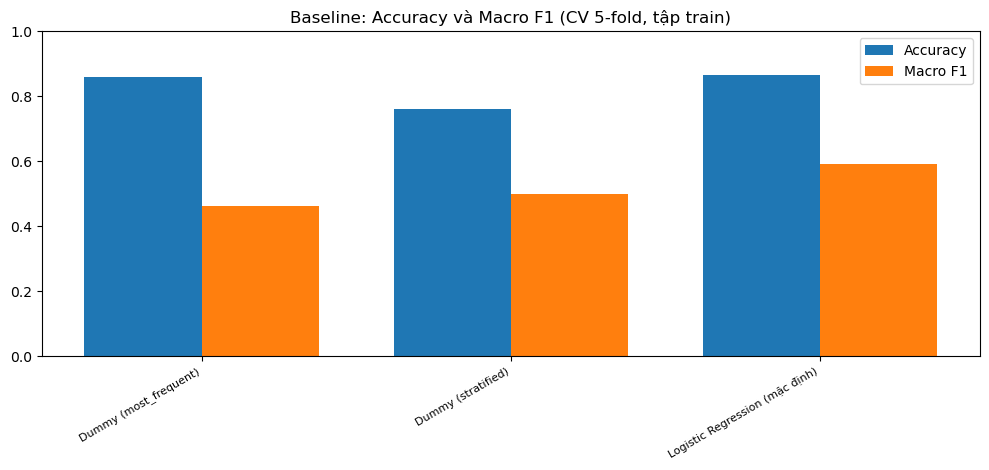

In [8]:
res06 = pd.DataFrame(results)
table06 = to_table(res06)
display(table06)

res06.to_csv(LOG_DIR / "results_06_baseline.csv", index=False, encoding="utf-8-sig")   # notebook 07 đọc file này
plot_bars(res06, "06_baseline_so_sanh.png", "Baseline: Accuracy và Macro F1 (CV 5-fold, tập train)")

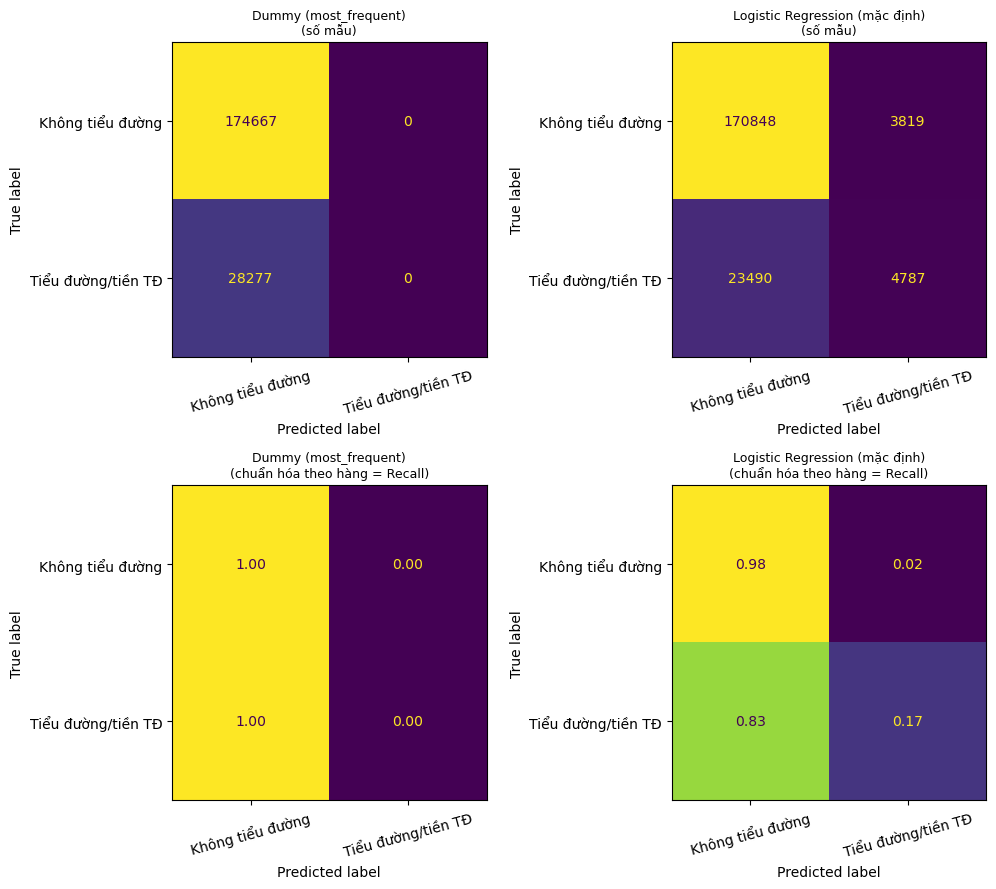

In [9]:
plot_confusion(["Dummy (most_frequent)", "Logistic Regression (mặc định)"], "06_confusion_matrix_baseline.png")

In [10]:
d = res06.set_index("Mô hình")
print("Dummy most_frequent: Accuracy =", round(d.loc["Dummy (most_frequent)", "Accuracy"], 4),
      "| Macro F1 =", round(d.loc["Dummy (most_frequent)", "Macro F1"], 4))
r = d.loc["Logistic Regression (mặc định)"]
print("LR mặc định        : Accuracy =", round(r["Accuracy"], 4), "| Macro F1 =", round(r["Macro F1"], 4),
      "| ROC-AUC =", round(r["ROC-AUC"], 4),
      f"| Recall {FOCUS_NAME} =", round(r[f"Recall {FOCUS_NAME}"], 4))

Dummy most_frequent: Accuracy = 0.8607 | Macro F1 = 0.4626
LR mặc định        : Accuracy = 0.8654 | Macro F1 = 0.5928 | ROC-AUC = 0.8253 | Recall Tiểu đường/tiền TĐ = 0.1693


### Nhận xét baseline (điền bằng số liệu thật sau khi chạy đầy đủ, `QUICK = False`)
- Dummy `most_frequent` có Accuracy = *(…)* nhưng Macro F1 chỉ = *(…)* → Accuracy không phản ánh đúng chất lượng khi dữ liệu mất cân bằng.
- Logistic Regression mặc định đạt Macro F1 = *(…)*, ROC-AUC = *(…)*; Recall lớp hiếm chỉ = *(…)* vì mô hình ưu tiên lớp đa số.
- Mốc để notebook 07 phải vượt: Macro F1 = *(…)*.